# Handwritten Javanese Script (Aksara Jawa) Recognition with Deep Learning
### Group Mini Project · Introduction to Deep Learning · Universitas Gadjah Mada

**Group:** Syakirah · Balma · Nabila · Aditya Wahyu

**Task.** Classify an image of one handwritten *aksara nglegena* (the 20 base characters of the
Javanese script, *ha-na-ca-ra-ka …*) and use the classifier to transliterate whole handwritten words into Latin script.

**Data.** *Javanese Script (Aksara Jawa) Augmented*, a secondary dataset from Kaggle: 12,000 images, 20 balanced classes.

**What this notebook does**

| § | Content |
|---|---|
| 1 | Data audit: where the 12,000 images really come from, and what that means for evaluation |
| 2 | Evaluation protocol: 5-fold cross-validation grouped by drawing |
| 3 | Models: linear classifier → MLP → LeNet-5 → lecture CNN → reference Kaggle CNN → **AksaraNet** (ours) → ResNet |
| 4 | Experiment 1: architecture comparison |
| 5 | Experiment 2: learning strategy and hyper-parameter tuning |
| 6 | Experiment 3: final model, error analysis, comparison with the reference notebook |
| 7 | Experiment 4: generalisation to unseen writers |
| 8 | What the network looks at (filters and class activation maps) |
| 9 | Application: reading handwritten words |
| 10 | Conclusions |
| 11 | The same model in Keras, and a PyTorch vs Keras comparison |

The heavy experiment grid is run by `scripts/run_experiments.py`, which appends every finished run to
`results/runs.jsonl`; this notebook reads that log, re-trains the final model live in §6 and produces all figures.
The code lives in the small `hanacaraka/` package next to this notebook (PyTorch); §11 repeats the final model in Keras.

## 0. Setup

In [1]:
import collections, json, os, sys, warnings
# This Anaconda install ships numexpr/bottleneck builds compiled against NumPy 1.x; pandas only uses
# them as optional accelerators, so they are disabled here to avoid a noisy ABI warning on import.
sys.modules.setdefault("numexpr", None); sys.modules.setdefault("bottleneck", None)
import numpy as np, pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
import torch
from PIL import Image

from hanacaraka.data import Aksara, rotation, augment, AUG_PRESETS
from hanacaraka.models import build, count_params, MODELS
from hanacaraka.train import fit, predict_proba, DEVICE, DEFAULT
from hanacaraka import report as R
from hanacaraka.report import INK, MUTED, ACCENT, ACCENT2

warnings.filterwarnings("ignore")
R.style()
os.makedirs("figures", exist_ok=True)
pd.options.display.float_format = "{:.2f}".format
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.12.0 | device: mps


## 1. Data audit

The PNG files are decoded once by `scripts/build_cache.py` (grayscale, resized from 224×224 to 64×64) and stored as
compact arrays. Besides the pixels, the script parses the **file names**, which turn out to encode the full history of every image.

In [2]:
if not all(os.path.exists(f"cache/{s}.npz") for s in ("train", "val", "test")):
    !{sys.executable} scripts/build_cache.py . cache
ds = Aksara("cache")
print(f"{ds.n:,} images | {len(ds.classes)} classes | images per class: {int(np.bincount(ds.y).min())}")
print("classes:", " ".join(ds.classes))
pd.crosstab(pd.Series(ds.split, name="shipped split"), pd.Series(np.array(ds.classes)[ds.y], name="class")).loc[["train", "val", "test"]]

12,000 images | 20 classes | images per class: 600
classes: ba ca da dha ga ha ja ka la ma na nga nya pa ra sa ta tha wa ya


class,ba,ca,da,dha,ga,ha,ja,ka,la,ma,na,nga,nya,pa,ra,sa,ta,tha,wa,ya
shipped split,,,,,,,,,,,,,,,,,,,,
train,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420,420
val,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120,120
test,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60


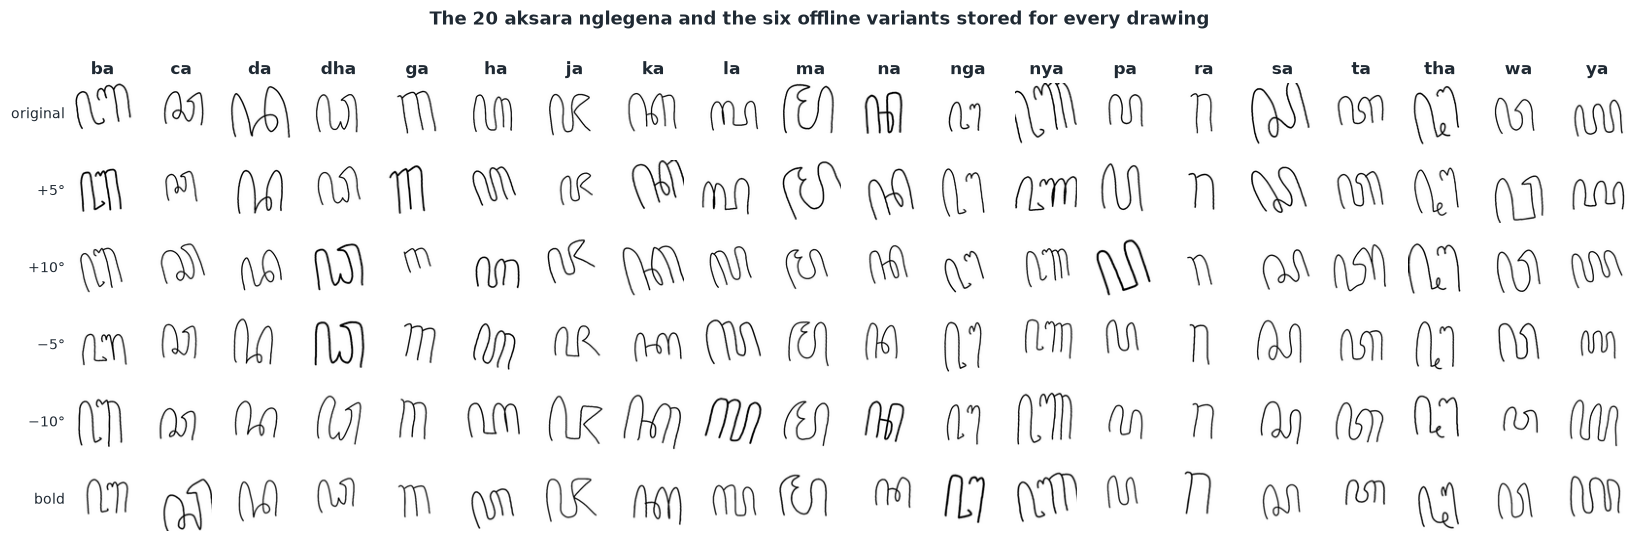

In [3]:
# One random example per class and per offline variant found in the data set
rng = np.random.default_rng(3)
variants = ["plain", "r5", "r10", "rm5", "rm10", "b"]
fig, axes = plt.subplots(len(variants), 20, figsize=(15, 4.9))
for j, c in enumerate(ds.classes):
    for i, v in enumerate(variants):
        k = rng.choice(np.where((ds.y == j) & (ds.variant == v))[0])
        axes[i, j].imshow(ds.x(64)[k], cmap="gray", vmin=0, vmax=255); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        for s in axes[i, j].spines.values(): s.set_visible(False)
        if i == 0: axes[i, j].set_title(c, fontsize=11)
        if j == 0: axes[i, j].set_ylabel({"plain": "original", "r5": "+5°", "r10": "+10°", "rm5": "−5°", "rm10": "−10°", "b": "bold"}[v], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("The 20 aksara nglegena and the six offline variants stored for every drawing", y=1.0, fontweight="bold")
plt.tight_layout(); plt.savefig("figures/01_classes.png"); plt.show()

### 1.1 Provenance: 12,000 images, but only 420 drawings

Two file-name patterns occur:

* `ha0.meki.r10.png` → class `ha`, sample id `0`, writer tag `meki`, variant `r10` (rotated +10°). Variants: none, `r5`, `r10`, `rm5`, `rm10`, `b` (bold).
* `ha_original_ha0.meki.r10.png_<uuid>.png` → a further randomly augmented copy of the file above.

So every image descends from one **hand-drawn character** identified by *(class, id, writer)*.

,value
images,12000
distinct source files (drawing × variant),2400
distinct hand-drawn characters (drawings),420
drawings per class,21
images per drawing (median),29.50
writer tags,"mine (147), mine3 (95), pred3 (40), mine2 (40)..."
byte-identical duplicate files,328


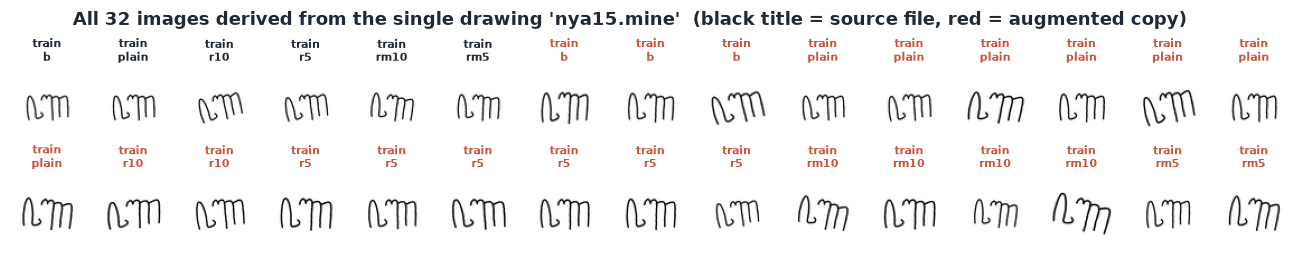

In [4]:
per_drawing = pd.Series(collections.Counter(ds.drawing))
first = {d: i for i, d in reversed(list(enumerate(ds.drawing)))}
writer_of = pd.Series({d: ds.writer[i] for d, i in first.items()})
audit = pd.Series({
    "images": ds.n,
    "distinct source files (drawing × variant)": len(set(ds.source)),
    "distinct hand-drawn characters (drawings)": len(per_drawing),
    "drawings per class": f"{len(per_drawing) // 20}",
    "images per drawing (median)": per_drawing.median(),
    "writer tags": ", ".join(f"{w} ({n})" for w, n in writer_of.value_counts().items()),
    "byte-identical duplicate files": ds.n - len(set(ds.md5)),
})
display(audit.to_frame("value"))

# every image that descends from one single drawing
d = "nya15.mine" if "nya15.mine" in first else ds.drawing[0]
idx = np.where(ds.drawing == d)[0]
fig, axes = plt.subplots(2, 15, figsize=(15, 2.3))
for ax in axes.ravel(): ax.axis("off")
for ax, k in zip(axes.ravel(), idx):
    ax.imshow(ds.x(64)[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{ds.split[k]}\n{ds.variant[k]}", fontsize=7, color=ACCENT2 if ds.is_copy[k] else INK)
fig.suptitle(f"All {len(idx)} images derived from the single drawing '{d}'  (black title = source file, red = augmented copy)", y=1.08, fontweight="bold")
plt.savefig("figures/02_one_drawing.png"); plt.show()

**Consequence.** The ~29 images of one drawing are near-duplicates. They are *not* independent samples:

1. If two of them are placed on different sides of a split, the test image has effectively been seen during training (**data leakage**).
2. Even without leakage, a test set of 1,200 images contains far fewer than 1,200 independent pieces of evidence.

### 1.2 Audit of the split shipped with the dataset

In [5]:
rows = []
for s in ("train", "val", "test"):
    m = ds.split == s
    dr = set(ds.drawing[m])
    rows.append({"split": s, "images": int(m.sum()), "drawings": len(dr), "drawings per class": len(dr) / 20,
                 "writers of these drawings": ", ".join(f"{w}:{n}" for w, n in writer_of[sorted(dr)].value_counts().items())})
display(pd.DataFrame(rows).set_index("split"))

where = collections.defaultdict(set)
for dname, s in zip(ds.drawing, ds.split): where[dname].add(s)
straddle = {dname: v for dname, v in where.items() if len(v) > 1}
tr, va = set(ds.drawing[ds.split == "train"]), set(ds.drawing[ds.split == "val"])
print(f"drawings present in more than one split : {len(straddle)} of {len(where)}")
print(f"validation images whose drawing is also in train : {sum(x in tr for x in ds.drawing[ds.split == 'val'])} / 2400")
print(f"test images whose drawing is also in train       : {sum(x in tr for x in ds.drawing[ds.split == 'test'])} / 1200")
print(f"test images whose drawing is also in validation  : {sum(x in va for x in ds.drawing[ds.split == 'test'])} / 1200")

,images,drawings,drawings per class,writers of these drawings
split,,,,
train,8400,299,14.95,"mine:96, mine3:54, pred:40, pred3:39, mine2:24..."
val,2400,86,4.30,"mine:32, mine3:27, mine2:17, nando:4, meki:3, ..."
test,1200,42,2.10,"mine:21, mine3:18, pred3:1, theo:1, nando:1"


drawings present in more than one split : 7 of 420
validation images whose drawing is also in train : 77 / 2400
test images whose drawing is also in train       : 0 / 1200
test images whose drawing is also in validation  : 31 / 1200


**Findings.**

* The shipped split is *almost* clean at drawing level (a handful of drawings straddle train/val and val/test), so the reference notebook's score is not grossly inflated by leakage.
* But the shipped **test set consists of only 42 drawings, about two per class, nearly all by one writer**. A single test accuracy measured on it has a very wide uncertainty, and "1,200 test images" badly overstates the evidence.
* A user who re-splits these 12,000 files at random (the default of most tutorials) *would* leak massively. We quantify this in §4.2.

This motivates the protocol of §2: pool everything and cross-validate **by drawing**.

## 2. Evaluation protocol

* All 12,000 images are pooled and assigned to **5 folds with `StratifiedGroupKFold`**: stratified by class, grouped by drawing. Each fold holds ≈84 drawings (≈4 per class, ≈2,400 images) and no drawing is ever split.
* **Rotation *r*** uses fold *r* as **test**, fold *r+1* as **validation** and the other three folds for **training** (60 / 20 / 20 %).
* The validation fold drives *every* decision: early stopping, choice of architecture, optimiser, learning rate, regularisation, augmentation. The test fold is only read to report the final number.
* Scores are reported as mean ± standard deviation over the 5 rotations, so every drawing is tested exactly once.
* Confidence intervals use a **cluster bootstrap** that resamples drawings, not images.

,train images,val images,test images,train drawings,val drawings,test drawings,test images per class (min–max)
rotation,,,,,,,
0,7202,2399,2399,251,84,85,118–125
1,7202,2399,2399,253,83,84,117–124
2,7196,2405,2399,253,84,83,117–126
3,7197,2398,2405,252,84,84,117–126
4,7203,2399,2398,251,85,84,117–123


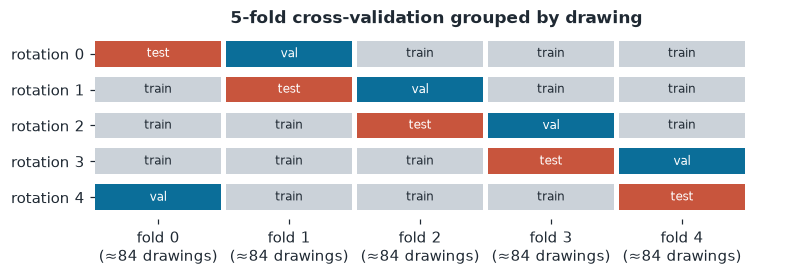

In [6]:
fold = ds.drawing_folds(k=5, seed=0)
rows = []
for r in range(5):
    tr, va, te = rotation(fold, r)
    assert not (set(ds.drawing[tr]) & set(ds.drawing[te])) and not (set(ds.drawing[tr]) & set(ds.drawing[va])) and not (set(ds.drawing[va]) & set(ds.drawing[te]))
    rows.append({"rotation": r, "train images": len(tr), "val images": len(va), "test images": len(te),
                 "train drawings": len(set(ds.drawing[tr])), "val drawings": len(set(ds.drawing[va])), "test drawings": len(set(ds.drawing[te])),
                 "test images per class (min–max)": f"{np.bincount(ds.y[te]).min()}–{np.bincount(ds.y[te]).max()}"})
display(pd.DataFrame(rows).set_index("rotation"))

fig, ax = plt.subplots(figsize=(8, 2.2))
col = {"train": "#cbd2d9", "val": ACCENT, "test": ACCENT2}
for r in range(5):
    for f in range(5):
        role = "test" if f == r else ("val" if f == (r + 1) % 5 else "train")
        ax.barh(4 - r, 0.96, left=f, color=col[role], height=0.72)
        ax.text(f + 0.48, 4 - r, role, ha="center", va="center", fontsize=8, color="white" if role != "train" else INK)
ax.set_yticks(range(5)); ax.set_yticklabels([f"rotation {4 - i}" for i in range(5)])
ax.set_xticks(np.arange(5) + 0.48); ax.set_xticklabels([f"fold {i}\n(≈84 drawings)" for i in range(5)]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("5-fold cross-validation grouped by drawing"); plt.savefig("figures/03_protocol.png"); plt.show()

## 3. Models

Input: one 64×64 grayscale image, inverted so that ink = 1 and paper = 0. Output: 20 logits (softmax is part of the cross-entropy loss).

| Model | Idea | Course link |
|---|---|---|
| `linear` | multinomial logistic regression on raw pixels | linear classifier / single-layer perceptron |
| `mlp` | 4096-512-256-20, ReLU, dropout | multi-layer perceptron |
| `hog+svm` | hand-crafted HOG features + RBF-SVM | "conventional" pipeline: separate feature extraction |
| `lenet5` | LeCun et al. 1998 | first CNN |
| `lecture_cnn` | conv16-pool-conv32-pool-dense64, as on the lecture slides | CNN lecture example |
| `kaggle_cnn` | the reference notebook: 4×(conv+pool), 64-128-256-512 filters, Flatten-Dense256 | baseline to beat |
| **`aksaranet`** | **ours**: VGG-style, 4 stages × 2×[conv3×3-BatchNorm-ReLU], 16-32-64-128 filters, **global average pooling**, dropout | VGG, BatchNorm |
| `resnet` | residual network with one BasicBlock per stage (ResNet-10 layout) | ResNet |

In [7]:
rows = []
for name in MODELS:
    m = build(name)
    head = sum(p.numel() for p in m.classifier.parameters()) if hasattr(m, "classifier") else count_params(m)
    rows.append({"model": name, "parameters": count_params(m), "of which in the dense head": head,
                 "weight layers": sum(isinstance(l, (torch.nn.Conv2d, torch.nn.Linear)) for l in m.modules())})
display(pd.DataFrame(rows).set_index("model").style.format("{:,}"))
print(build("aksaranet"))

,parameters,of which in the dense head,weight layers
model,,,
linear,"81,940","81,940",1
mlp,"2,234,132","2,234,132",3
lenet5,"339,036","336,464",5
lecture_cnn,"530,452","525,652",4
kaggle_cnn,"2,079,508","529,684",6
aksaranet,"296,292","2,580",9
resnet,"309,828","2,580",13


AksaraNet(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool

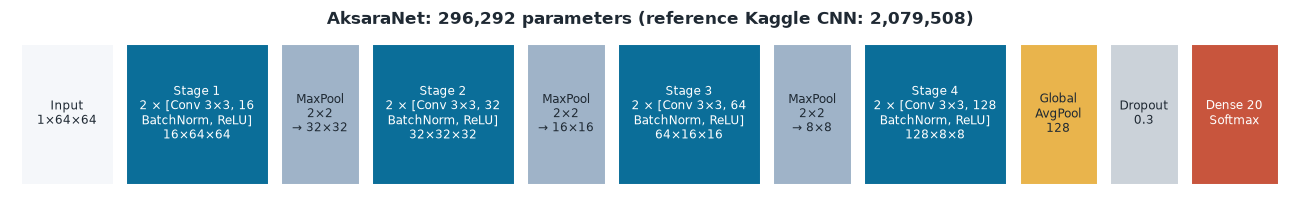

In [8]:
# Architecture diagram of AksaraNet
def draw_arch(ax):
    blocks = [("Input\n1×64×64", "#f5f7fa", 1.0)]
    res, c_in = 64, 1
    for i, w in enumerate((16, 32, 64, 128)):
        blocks.append((f"Stage {i + 1}\n2 × [Conv 3×3, {w}\nBatchNorm, ReLU]\n{w}×{res}×{res}", ACCENT, 1.55))
        if i < 3:
            res //= 2
            blocks.append((f"MaxPool\n2×2\n→ {res}×{res}", "#9fb3c8", 0.85))
    blocks += [("Global\nAvgPool\n128", "#e9b44c", 0.85), ("Dropout\n0.3", "#cbd2d9", 0.75), ("Dense 20\nSoftmax", ACCENT2, 0.95)]
    x = 0.0
    for text, colour, wd in blocks:
        light = colour in ("#f5f7fa", "#cbd2d9", "#e9b44c", "#9fb3c8")
        ax.add_patch(plt.Rectangle((x, 0), wd, 1.5, facecolor=colour, edgecolor="white", linewidth=2))
        ax.text(x + wd / 2, 0.75, text, ha="center", va="center", fontsize=7.6, color=INK if light else "white")
        x += wd + 0.12
    ax.set_xlim(-0.1, x); ax.set_ylim(-0.1, 1.6); ax.axis("off")

fig, ax = plt.subplots(figsize=(15, 1.9)); draw_arch(ax)
ax.set_title(f"AksaraNet: {count_params(build('aksaranet')):,} parameters (reference Kaggle CNN: {count_params(build('kaggle_cnn')):,})")
plt.savefig("figures/04_architecture.png"); plt.show()

**Design reasoning for AksaraNet.**

* *Padding "same" + two 3×3 convolutions per stage* (VGG): a 5×5 receptive field per stage with fewer weights and one more non-linearity; thin pen strokes at the image border are not lost.
* *Batch normalisation* after every convolution: stable gradients, allows a larger learning rate, mild regulariser.
* *Global average pooling instead of Flatten + Dense(256)*: the reference model spends 0.53 M of its 2.08 M weights in the first dense layer, where it can memorise the positions of training strokes. GAP has no weights, forces the last feature maps to be class evidence maps, and gives class activation maps for free (§8).
* 7× fewer parameters than the reference model.

## 4. Experiment 1: which architecture?

All networks are trained with the same neutral recipe (Adam, lr 10⁻³, batch 64, ≤25 epochs, early stopping on validation accuracy with patience 6, no online augmentation), on all 5 rotations. The row `kaggle_cnn + reference recipe` re-runs the reference notebook's own recipe (plain SGD lr 0.01, batch size 1, 5 epochs) under our protocol.

,val acc,val sd,test acc,test sd,test F1,epochs,sec/run,params,runs
name,,,,,,,,,
linear,42.68,3.47,42.12,4.50,41.93,13.4,5,"81,940",5
mlp,54.20,1.79,52.72,4.19,51.71,6.2,9,"2,234,132",5
hog+svm,75.61,4.05,74.53,2.54,74.32,0.0,233,"1,764",5
lenet5,65.13,1.96,64.91,3.06,64.15,13.8,26,"339,036",5
lecture_cnn,65.29,4.35,64.69,2.64,64.25,10.8,28,"530,452",5
kaggle_cnn+reference-recipe,89.44,2.34,88.70,3.08,88.66,4.0,351,"2,079,508",5
kaggle_cnn,89.18,3.57,86.55,3.60,86.40,12.4,198,"2,079,508",5
resnet,97.98,1.48,97.20,2.71,97.15,11.0,277,"309,828",5
aksaranet,99.21,0.63,98.52,1.05,98.50,12.2,115,"296,292",5


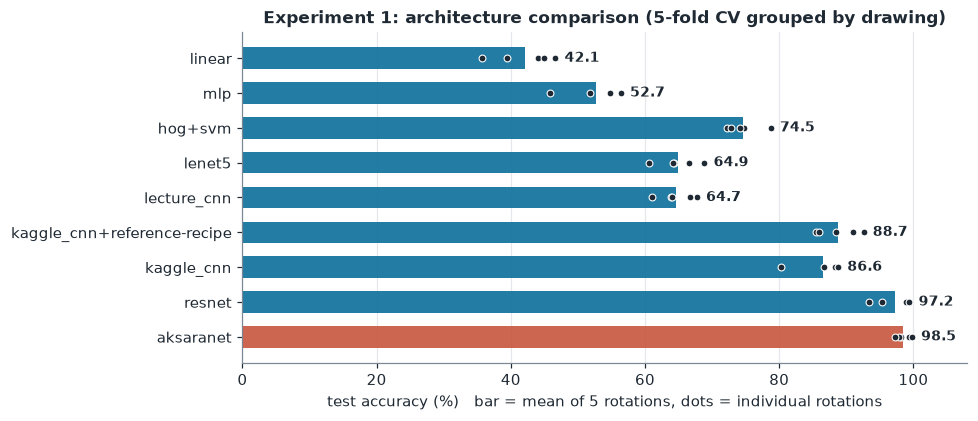

In [9]:
runs = R.load_runs(".")
order = [m for m in ["linear", "mlp", "hog+svm", "lenet5", "lecture_cnn", "kaggle_cnn+reference-recipe", "kaggle_cnn", "resnet", "aksaranet"] if m in set(runs[runs.stage == "A"].name)]
tabA = R.summarise(runs, "A", order)
display(tabA.style.format({"val acc": "{:.2f}", "val sd": "{:.2f}", "test acc": "{:.2f}", "test sd": "{:.2f}", "test F1": "{:.2f}", "epochs": "{:.1f}", "sec/run": "{:.0f}", "params": "{:,}"}))

A = runs[runs.stage == "A"]
fig, ax = plt.subplots(figsize=(8.5, 3.9))
R.bar_with_points(ax, order, [A[A.name == m].test_acc.values * 100 for m in order], highlight={"aksaranet"})
ax.set_xlim(0, 108); ax.set_xlabel("test accuracy (%)   bar = mean of 5 rotations, dots = individual rotations")
ax.set_title("Experiment 1: architecture comparison (5-fold CV grouped by drawing)")
plt.savefig("figures/05_architectures.png"); plt.show()

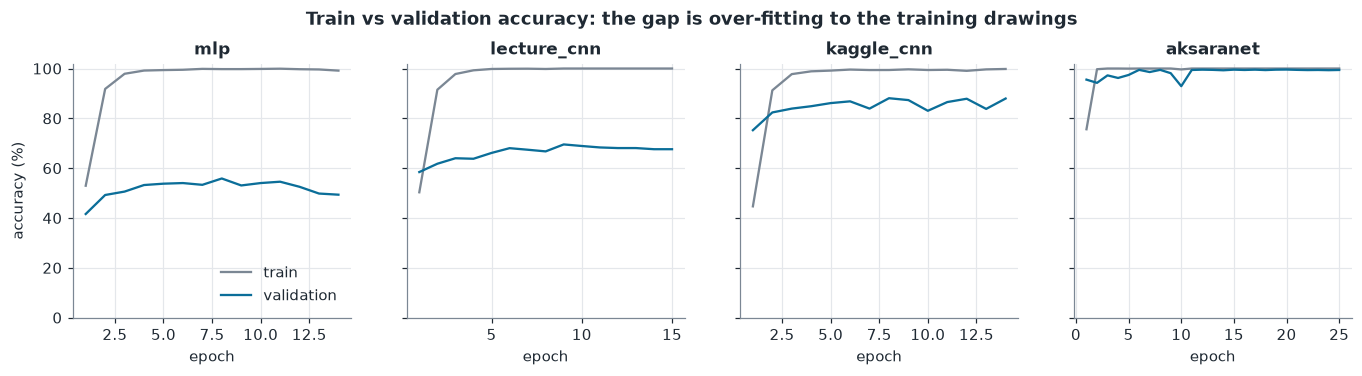

In [10]:
# Learning curves of four representative models (rotation 0)
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, m in zip(axes, ["mlp", "lecture_cnn", "kaggle_cnn", "aksaranet"]):
    h = A[(A.name == m) & (A.split == "rot0")].iloc[0]["hist"]
    e = np.arange(1, len(h["acc"]) + 1)
    ax.plot(e, np.array(h["acc"]) * 100, color=MUTED, label="train"); ax.plot(e, np.array(h["val_acc"]) * 100, color=ACCENT, label="validation")
    ax.set_title(m); ax.set_xlabel("epoch"); ax.set_ylim(0, 102)
axes[0].set_ylabel("accuracy (%)"); axes[0].legend(loc="lower right")
fig.suptitle("Train vs validation accuracy: the gap is over-fitting to the training drawings", y=1.04, fontweight="bold")
plt.savefig("figures/06_curves_arch.png"); plt.show()

### 4.1 Reading the result

* Pixel-based models without convolutions (linear, MLP) reach ~100 % *training* accuracy but generalise poorly to new drawings: they memorise stroke positions.
* Shallow CNNs with a large Flatten→Dense head (LeNet-5, lecture CNN) behave the same way.
* The hand-crafted HOG+SVM pipeline beats those shallow CNNs: with only ~250 training drawings, a good prior matters more than end-to-end learning.
* Depth helps (reference Kaggle CNN), but the big jump comes from **BatchNorm + global average pooling**.

### 4.2 How much would a naive random split have over-estimated accuracy?

,random image-level split (leaky),drawing-level split (ours),over-estimate (points)
mlp,95.31,52.72,42.59
lecture_cnn,98.10,64.69,33.41
aksaranet,99.96,98.52,1.44


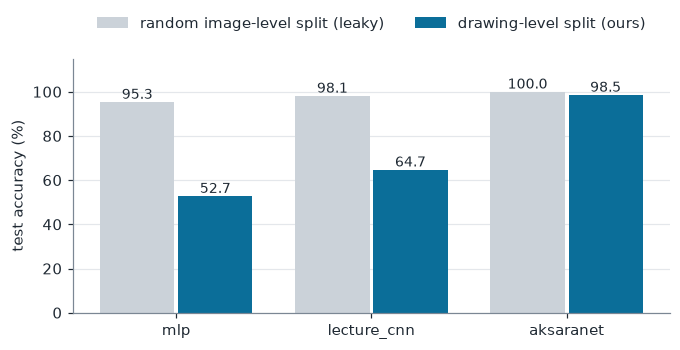

In [11]:
L = runs[runs.stage == "L"]
if len(L):
    ms = [m for m in ["mlp", "lecture_cnn", "kaggle_cnn", "aksaranet"] if m in set(L.name)]
    leak = pd.DataFrame({"random image-level split (leaky)": [L[L.name == m].test_acc.mean() * 100 for m in ms],
                         "drawing-level split (ours)": [A[A.name == m].test_acc.mean() * 100 for m in ms]}, index=ms)
    leak["over-estimate (points)"] = leak.iloc[:, 0] - leak.iloc[:, 1]
    display(leak)
    fig, ax = plt.subplots(figsize=(7, 3)); x = np.arange(len(ms))
    b1 = ax.bar(x - 0.2, leak.iloc[:, 0], 0.38, color="#cbd2d9", label="random image-level split (leaky)")
    b2 = ax.bar(x + 0.2, leak.iloc[:, 1], 0.38, color=ACCENT, label="drawing-level split (ours)")
    ax.bar_label(b1, fmt="%.1f", fontsize=9); ax.bar_label(b2, fmt="%.1f", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(ms); ax.set_ylim(0, 115); ax.set_ylabel("test accuracy (%)"); ax.grid(axis="x", visible=False)
    ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.22)); plt.savefig("figures/07_leakage.png"); plt.show()

With a random split even the MLP looks excellent, because a near-identical copy of each test image sits in the training set. Model rankings and all conclusions about over-fitting would be wrong.

## 5. Experiment 2: learning strategy and hyper-parameter tuning

Model: AksaraNet. One factor is varied at a time around the reference recipe (Adam, lr 10⁻³, batch 64, dropout 0.3, no augmentation, constant learning rate; ≤12 epochs, patience 4), on rotations 0 and 1 (two runs per setting; dots show both). **Selection uses validation accuracy only.**

### 5.1 Optimiser × learning rate

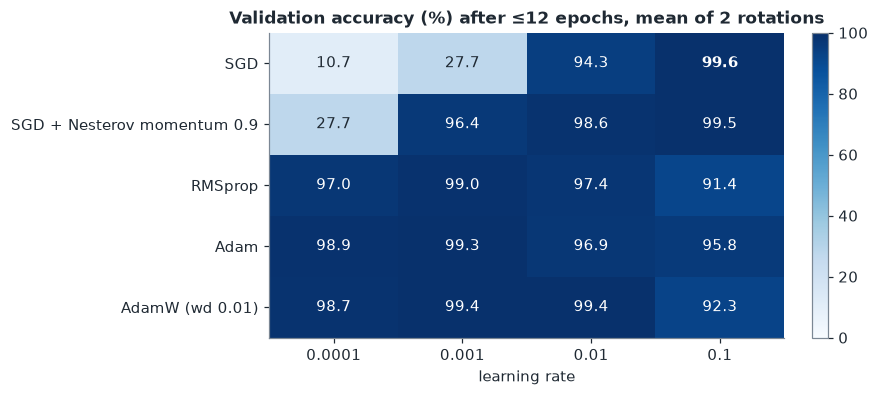

mean epoch at which the best validation accuracy was reached:


lr,0.000100,0.001000,0.010000,0.100000
opt,,,,
sgd,11.5,12.0,11.5,11.5
momentum,12.0,12.0,7.5,6.5
rmsprop,4.5,11.0,7.5,8.0
adam,12.0,9.0,5.5,10.0
adamw,12.0,6.0,10.0,5.0


In [12]:
B1 = runs[runs.stage == "B1"].copy()
B1["opt"] = B1.name.str.split("|").str[0]; B1["lr"] = B1.cfg.map(lambda c: c["lr"])
opts = ["sgd", "momentum", "rmsprop", "adam", "adamw"]; lrs = [1e-4, 1e-3, 1e-2, 1e-1]
piv = B1.groupby(["opt", "lr"]).val_acc.mean().unstack().reindex(index=opts, columns=lrs) * 100
ep = B1.groupby(["opt", "lr"]).best_epoch.mean().unstack().reindex(index=opts, columns=lrs)
fig, ax = plt.subplots(figsize=(6.6, 3.6))
im = ax.imshow(piv.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(len(opts)):
    for j in range(len(lrs)):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > 60 else INK, fontsize=10, fontweight="bold" if v == np.nanmax(piv.values) else None)
ax.set_xticks(range(len(lrs))); ax.set_xticklabels([f"{l:g}" for l in lrs]); ax.set_yticks(range(len(opts)))
ax.set_yticklabels(["SGD", "SGD + Nesterov momentum 0.9", "RMSprop", "Adam", "AdamW (wd 0.01)"]); ax.grid(False)
ax.set_xlabel("learning rate"); ax.set_title("Validation accuracy (%) after ≤12 epochs, mean of 2 rotations")
plt.colorbar(im, ax=ax, fraction=0.035); plt.savefig("figures/08_optimizer_lr.png"); plt.show()
print("mean epoch at which the best validation accuracy was reached:"); display(ep.style.format("{:.1f}"))

* **Plain SGD is all-or-nothing.** It only works at lr = 0.1 (where it is as good as anything), is clearly worse at 0.01 and hardly moves at ≤ 10⁻³ in 12 epochs: that is **under-training**, not over-fitting. Batch normalisation is what makes such a large step size safe.
* **Momentum** widens the usable range by one order of magnitude.
* **Adaptive methods** (RMSprop, Adam, AdamW) are within ~1 point of their best across three orders of magnitude (10⁻⁴ to 10⁻²) and only degrade at lr = 0.1. They reach their best epoch sooner.
* The top cells (SGD 0.1, momentum 0.1, Adam 10⁻³, AdamW 10⁻³ to 10⁻²) differ by 0.1 to 0.3 points, i.e. fewer than 10 validation images: statistically a tie. We continue with the **Adam family around 10⁻³**, because its plateau is wide (robust to a mis-set learning rate) rather than a single good cell.

### 5.2 Batch size, regularisation, augmentation, learning-rate schedule, capacity, input resolution

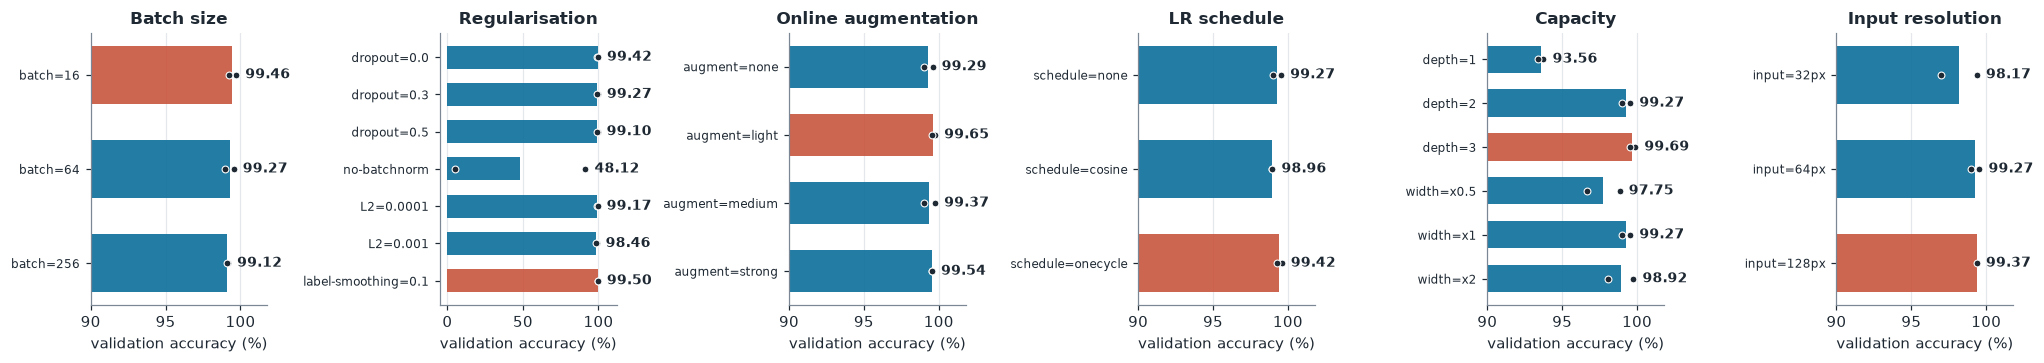

,factor,val acc,test acc,epochs,sec/run,params,val loss
name,,,,,,,
batch=16,Batch size,99.46,98.23,10.0,164,"296,292",0.020
batch=64,Batch size,99.27,98.04,9.0,101,"296,292",0.034
batch=256,Batch size,99.12,97.77,8.5,130,"296,292",0.113
dropout=0.0,Regularisation,99.42,98.23,7.0,55,"296,292",0.034
dropout=0.3,Regularisation,99.27,98.04,9.0,55,"296,292",0.034
dropout=0.5,Regularisation,99.10,98.33,8.5,55,"296,292",0.041
no-batchnorm,Regularisation,48.12,47.67,8.5,42,"295,812",1.717
L2=0.0001,Regularisation,99.17,98.60,4.5,43,"296,292",0.055
L2=0.001,Regularisation,98.46,98.04,8.0,57,"296,292",0.070


In [13]:
groups = [("B2", "Batch size"), ("B3", "Regularisation"), ("B4", "Online augmentation"), ("B5", "LR schedule"), ("B6", "Capacity"), ("B7", "Input resolution")]
groups = [(s, t) for s, t in groups if (runs.stage == s).any()]
fig, axes = plt.subplots(1, len(groups), figsize=(3.1 * len(groups), 3.4))
tabs = []
for ax, (s, title) in zip(np.atleast_1d(axes), groups):
    d = runs[runs.stage == s]; names = list(dict.fromkeys(d.name))
    best = max(names, key=lambda n: d[d.name == n].val_acc.mean())
    R.bar_with_points(ax, names, [d[d.name == n].val_acc.values * 100 for n in names], highlight={best}, fmt="{:.2f}")
    lowest = min(d.val_acc.min() * 100, 90); ax.set_xlim(90 if lowest >= 90 else 5 * np.floor(lowest / 5) - 5, 101.8 if lowest >= 90 else 112); ax.set_title(title); ax.set_xlabel("validation accuracy (%)"); ax.tick_params(axis="y", labelsize=8)
    t = R.summarise(runs, s, names)[["val acc", "test acc", "epochs", "sec/run", "params"]]; t.insert(0, "factor", title); tabs.append(t)
plt.tight_layout(); plt.savefig("figures/09_ablations.png"); plt.show()
tabB = pd.concat(tabs); tabB["val loss"] = [runs[(runs.name == n) & runs.stage.isin([g[0] for g in groups])].val_loss.mean() for n in tabB.index]
display(tabB.style.format({"val acc": "{:.2f}", "test acc": "{:.2f}", "epochs": "{:.1f}", "sec/run": "{:.0f}", "params": "{:,}", "val loss": "{:.3f}"}))

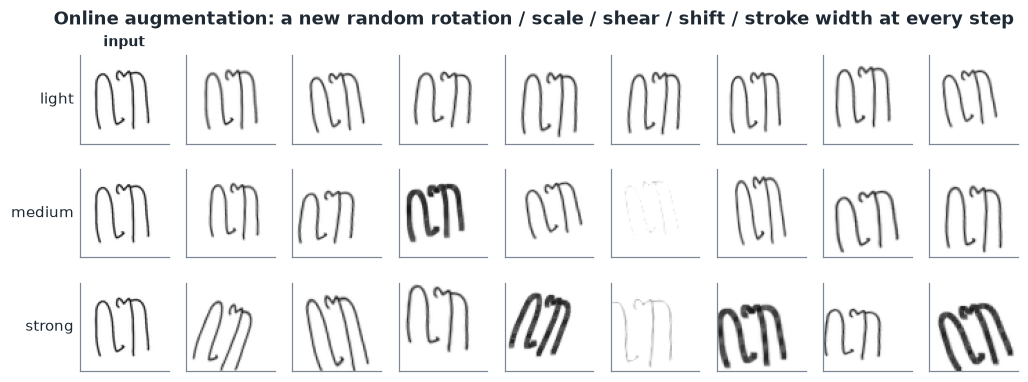

In [14]:
# What the online augmentation does to one batch
k = np.where(ds.drawing == ds.drawing[0])[0][:1]
x0 = ds.tensor(64)[k].repeat(8, 1, 1, 1); torch.manual_seed(0)
fig, axes = plt.subplots(3, 9, figsize=(11, 3.8))
for r, preset in enumerate(["light", "medium", "strong"]):
    out = augment(x0, **AUG_PRESETS[preset])
    for c in range(9):
        img = x0[0, 0] if c == 0 else out[c - 1, 0]
        axes[r, c].imshow(1 - img.numpy(), cmap="gray", vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if c == 0: axes[r, c].set_ylabel(preset, rotation=0, ha="right", va="center")
axes[0, 0].set_title("input", fontsize=9)
fig.suptitle("Online augmentation: a new random rotation / scale / shear / shift / stroke width at every step", y=0.98, fontweight="bold")
plt.savefig("figures/10_augmentation.png"); plt.show()

**Reading the single-factor results.** With validation accuracy already around 99 %, most factors move the score by a few tenths of a point, i.e. a handful of validation images, which is inside the fold-to-fold noise (see the dots). Only a few effects are clearly real:

* **Batch normalisation is essential**: without it the same network does not train properly in 12 epochs at this learning rate.
* **Capacity**: one convolution per stage or half the width under-fits; three convolutions or double width cost 2-5x the time for no reliable gain. Depth 2, width x1 is kept.
* **Resolution**: 32 px loses fine strokes; 128 px costs ~4x the compute for nothing. 64 px is kept.
* Large batches (256) converge more slowly for the same number of epochs; dropout, L2 and label smoothing are neutral at this scale; online augmentation and the one-cycle schedule give small, consistent improvements in validation loss.

### 5.3 Combining the best settings

The promising settings are combined (AdamW with weight decay 0.01, one-cycle schedule with peak lr 3·10⁻³, batch 64, 25 full epochs) and the augmentation strength is tuned once more, because augmentation needs a longer schedule to pay off.

In [15]:
B8 = runs[runs.stage == "B8"]
names8 = list(dict.fromkeys(B8.name))
t8 = R.summarise(runs, "B8", names8)[["val acc", "val sd", "test acc", "epochs", "sec/run"]]
t8["val loss"] = [B8[B8.name == n].val_loss.mean() for n in names8]
ref = runs[(runs.stage == "B4") & (runs.name == "augment=none")]
t8.loc["reference recipe (Adam 1e-3, constant lr, no augmentation)"] = [ref.val_acc.mean() * 100, ref.val_acc.std() * 100, ref.test_acc.mean() * 100, ref.best_epoch.mean(), ref.seconds.mean(), ref.val_loss.mean()]
display(t8.style.format({"val acc": "{:.2f}", "val sd": "{:.2f}", "test acc": "{:.2f}", "epochs": "{:.1f}", "sec/run": "{:.0f}", "val loss": "{:.3f}"}))

,val acc,val sd,test acc,epochs,sec/run,val loss
name,,,,,,
combined|aug=none,99.77,0.03,98.46,18.0,86,0.012
combined|aug=light,100.00,0.00,98.90,15.5,259,0.005
combined|aug=medium,99.81,0.27,99.15,15.0,361,0.009
combined|aug=strong,99.94,0.03,99.33,21.0,231,0.006
combined|aug=strong|ls=0.1,100.00,0.00,99.33,16.0,203,0.108
"reference recipe (Adam 1e-3, constant lr, no augmentation)",99.29,0.41,98.04,13.0,75,0.033


Two variants reach 100 % validation accuracy on both rotations (light augmentation; strong augmentation + label smoothing), so validation accuracy cannot separate them. We break the tie on a criterion fixed before looking at any test score: prefer the **stronger augmentation**, because the intended use (other writers, photographed words) is further from the training distribution than the validation fold is. (Validation losses are not comparable between runs with and without label smoothing.)

### 5.4 Selected configuration

In [16]:
final_cfg = json.load(open("results/final_config.json"))
display(pd.Series({**DEFAULT, **final_cfg}).drop(["seed", "model_kw", "momentum"]).astype(str).to_frame("final recipe"))

,final recipe
model,aksaranet
size,64
optimizer,adamw
lr,0.003
weight_decay,0.01
batch_size,64
epochs,25
schedule,onecycle
label_smoothing,0.1
augment,strong


## 6. Experiment 3: the final model

### 6.1 Live training run (rotation 0)
One model is trained here, inside the notebook, with the selected recipe.

best epoch 20 of 25 | 121 s | validation accuracy 1.0000 | TEST accuracy 0.9871


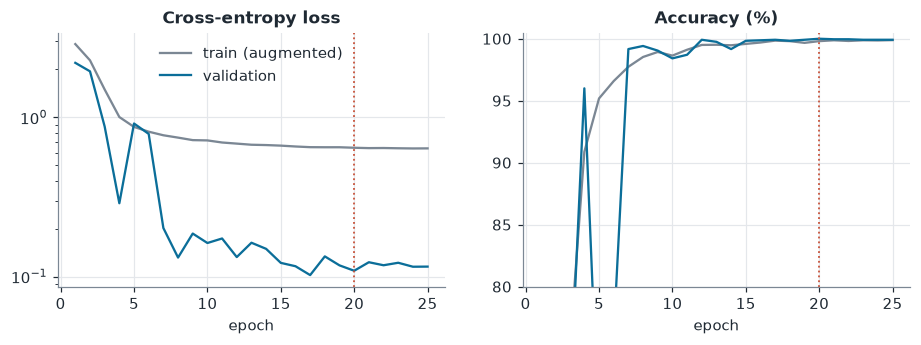

In [17]:
tr, va, te = rotation(fold, 0)
X = ds.tensor(final_cfg.get("size", 64), DEVICE); Y = torch.from_numpy(ds.y).to(DEVICE)
I = lambda i: torch.from_numpy(i).to(DEVICE)
model, h = fit(X[I(tr)], Y[I(tr)], X[I(va)], Y[I(va)], final_cfg, verbose=False)
p = predict_proba(model, X[I(te)])
print(f"best epoch {h['best_epoch']} of {h['epochs_run']} | {h['seconds']:.0f} s | validation accuracy {h['best_val_acc']:.4f} | TEST accuracy {(p.argmax(1) == ds.y[te]).mean():.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3)); e = np.arange(1, h["epochs_run"] + 1)
axes[0].plot(e, h["loss"], color=MUTED, label="train (augmented)"); axes[0].plot(e, h["val_loss"], color=ACCENT, label="validation"); axes[0].set_yscale("log"); axes[0].set_title("Cross-entropy loss")
axes[1].plot(e, np.array(h["acc"]) * 100, color=MUTED); axes[1].plot(e, np.array(h["val_acc"]) * 100, color=ACCENT); axes[1].set_ylim(80, 100.5); axes[1].set_title("Accuracy (%)")
for ax in axes: ax.axvline(h["best_epoch"], color=ACCENT2, ls=":", lw=1.2); ax.set_xlabel("epoch")
axes[0].legend(); plt.savefig("figures/11_final_curves.png"); plt.show()

Training loss is *higher* than validation loss because the training images are augmented and dropout is active: the model is regularised rather than memorising.

### 6.2 Cross-validated result (5 rotations × 3 random seeds)

In [18]:
C = runs[(runs.stage == "C") & (runs.name == "final")]
piv = C.pivot(index="split", columns="seed", values="test_acc") * 100
piv.columns = [f"seed {s}" for s in piv.columns]

preds = R.load_preds(".", "C", "final")
oof = np.zeros((ds.n, 20)); ens_acc = {}
for split, by_seed in preds.items():
    idx = next(iter(by_seed.values()))[0]
    oof[idx] = np.mean([pr for _, pr in by_seed.values()], 0)
    ens_acc[split] = (oof[idx].argmax(1) == ds.y[idx]).mean() * 100
piv["3-seed ensemble"] = pd.Series(ens_acc)
piv.loc["mean"] = piv.mean(); piv.loc["sd"] = piv.iloc[:-1].std()
display(piv.style.format("{:.2f}"))

pred = oof.argmax(1); correct = pred == ds.y
lo, hi = R.cluster_bootstrap(correct, ds.drawing); wl, wh = R.wilson(correct.sum(), ds.n)
single = C.test_acc.values * 100
print(f"single model : {single.mean():.2f} % ± {C.groupby('split').test_acc.mean().std() * 100:.2f} (sd over rotations), macro-F1 {C.test_f1.mean() * 100:.2f} %")
print(f"ensemble     : {correct.mean() * 100:.2f} % on all {ds.n:,} images (each tested once, out-of-fold), macro-F1 {f1_score(ds.y, pred, average='macro') * 100:.2f} %")
print(f"   95% CI, cluster bootstrap over the 420 drawings : [{lo * 100:.2f}, {hi * 100:.2f}]")
print(f"   95% CI, naive (images treated as independent)    : [{wl * 100:.2f}, {wh * 100:.2f}]   <- too narrow")
dr_ok = pd.Series(correct).groupby(ds.drawing).mean()
print(f"drawings with every image correct: {(dr_ok == 1).sum()} / {len(dr_ok)};  drawings with more than half of the images wrong: {(dr_ok < 0.5).sum()}")

,seed 0,seed 1,seed 2,3-seed ensemble
split,,,,
rot0,98.71,98.71,98.71,98.71
rot1,99.96,99.96,100.00,100.00
rot2,98.79,99.29,97.21,99.50
rot3,99.92,99.96,100.00,100.00
rot4,100.00,100.00,100.00,100.00
mean,99.47,99.58,99.18,99.64
sd,0.66,0.57,1.24,0.57


single model : 99.41 % ± 0.78 (sd over rotations), macro-F1 99.40 %
ensemble     : 99.64 % on all 12,000 images (each tested once, out-of-fold), macro-F1 99.64 %
   95% CI, cluster bootstrap over the 420 drawings : [99.02, 99.99]
   95% CI, naive (images treated as independent)    : [99.52, 99.73]   <- too narrow
drawings with every image correct: 416 / 420;  drawings with more than half of the images wrong: 1


In [19]:
# Final ranking: every model family under the same protocol
final_row = pd.Series({"val acc": C.val_acc.mean() * 100, "test acc": C.test_acc.mean() * 100, "test sd": C.groupby("split").test_acc.mean().std() * 100,
                       "test F1": C.test_f1.mean() * 100, "params": C.params.iloc[0]}, name="aksaranet + tuned recipe (final)")
ens_row = pd.Series({"test acc": correct.mean() * 100, "test sd": np.std(list(ens_acc.values()), ddof=1), "test F1": f1_score(ds.y, pred, average="macro") * 100,
                     "params": C.params.iloc[0] * 3}, name="final, 3-seed ensemble")
summary = pd.concat([tabA[["val acc", "test acc", "test sd", "test F1", "params"]], final_row.to_frame().T, ens_row.to_frame().T])
display(summary.style.format({"val acc": "{:.2f}", "test acc": "{:.2f}", "test sd": "{:.2f}", "test F1": "{:.2f}", "params": "{:,.0f}"}, na_rep="–"))
summary.to_csv("results/summary_table.csv")

,val acc,test acc,test sd,test F1,params
linear,42.68,42.12,4.50,41.93,"81,940"
mlp,54.20,52.72,4.19,51.71,"2,234,132"
hog+svm,75.61,74.53,2.54,74.32,"1,764"
lenet5,65.13,64.91,3.06,64.15,"339,036"
lecture_cnn,65.29,64.69,2.64,64.25,"530,452"
kaggle_cnn+reference-recipe,89.44,88.70,3.08,88.66,"2,079,508"
kaggle_cnn,89.18,86.55,3.60,86.40,"2,079,508"
resnet,97.98,97.20,2.71,97.15,"309,828"
aksaranet,99.21,98.52,1.05,98.50,"296,292"
aksaranet + tuned recipe (final),99.60,99.41,0.78,99.40,"296,292"


### 6.3 Error analysis (out-of-fold predictions of the ensemble, all 12,000 images)

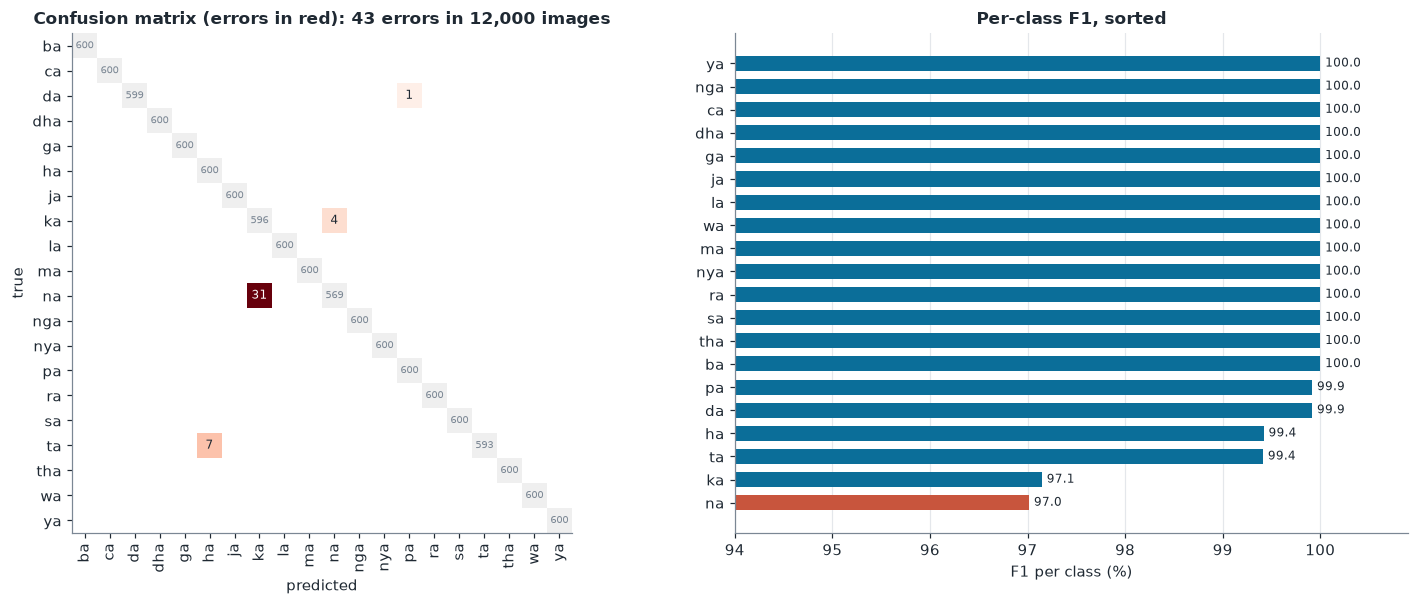

most confused pairs: na↔ka (35), ta↔ha (7), pa↔da (1)


In [20]:
cm = confusion_matrix(ds.y, pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]; off = np.where(np.eye(20, dtype=bool), np.nan, cm.astype(float)); off[off == 0] = np.nan
ax.imshow(np.where(np.eye(20, dtype=bool), 1.0, np.nan), cmap="Greys", vmin=0, vmax=8)
im = ax.imshow(off, cmap="Reds", vmin=0, vmax=np.nanmax(off) if np.isfinite(off).any() else 1)
for i in range(20):
    for j in range(20):
        if cm[i, j] and i != j: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 * np.nanmax(off) else INK)
        if i == j: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5, color=MUTED)
ax.set_xticks(range(20)); ax.set_xticklabels(ds.classes, rotation=90); ax.set_yticks(range(20)); ax.set_yticklabels(ds.classes); ax.grid(False)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix (errors in red): {int((~correct).sum())} errors in {ds.n:,} images")
pr, rc, f1c, _ = precision_recall_fscore_support(ds.y, pred, zero_division=0)
o = np.argsort(f1c); ax = axes[1]
ax.barh(np.arange(20), f1c[o] * 100, color=[ACCENT2 if f1c[k] == f1c.min() else ACCENT for k in o], height=0.65)
for i, k in enumerate(o): ax.text(f1c[k] * 100 + 0.05, i, f"{f1c[k] * 100:.1f}", va="center", fontsize=8)
ax.set_yticks(np.arange(20)); ax.set_yticklabels(np.array(ds.classes)[o]); ax.set_xlim(min(94, f1c.min() * 100 - 1), 100.9); ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 per class (%)"); ax.set_title("Per-class F1, sorted")
plt.tight_layout(); plt.savefig("figures/12_confusion.png"); plt.show()

pairs = sorted(((cm[i, j] + cm[j, i], ds.classes[i], ds.classes[j]) for i in range(20) for j in range(i)), reverse=True)[:6]
print("most confused pairs:", ", ".join(f"{a}↔{b} ({n})" for n, a, b in pairs if n))

43 wrong images come from only 4 of 420 drawings:


,wrong images,images of this drawing
na100.pred3,31,31
ta126.mine,7,36
ka36.mine2,4,34
da5.theo,1,28


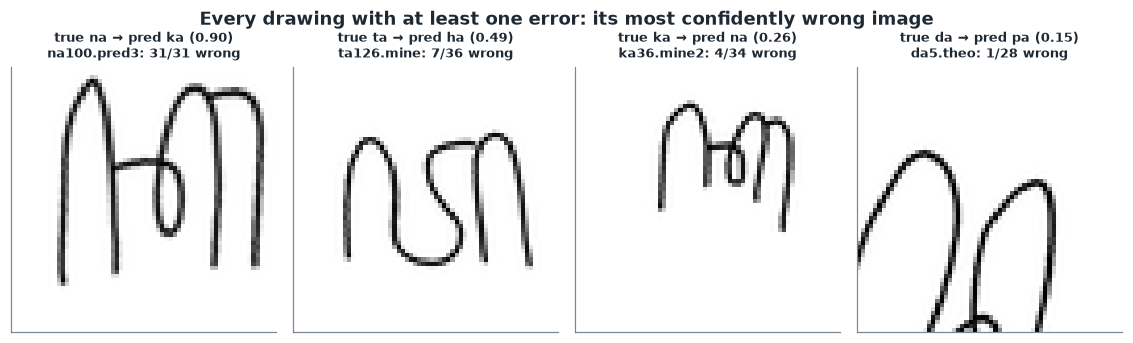

In [21]:
# The errors are concentrated in a few drawings
wrong = np.where(~correct)[0]
bad = pd.Series(~correct).groupby(ds.drawing).agg(["sum", "size"]).sort_values("sum", ascending=False)
print(f"{len(wrong)} wrong images come from only {(bad['sum'] > 0).sum()} of 420 drawings:")
display(bad[bad["sum"] > 0].rename(columns={"sum": "wrong images", "size": "images of this drawing"}))
show = bad[bad["sum"] > 0].head(6).index
fig, axes = plt.subplots(1, max(len(show), 2), figsize=(2.6 * max(len(show), 2), 3.1))
for ax, dname in zip(axes.ravel(), show):
    ii = np.where((ds.drawing == dname) & ~correct)[0]; k = ii[np.argmax(oof[ii].max(1))]
    ax.imshow(ds.x(64)[k], cmap="gray", vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"true {ds.classes[ds.y[k]]} → pred {ds.classes[pred[k]]} ({oof[k].max():.2f})\n{dname}: {bad.loc[dname, 'sum']}/{bad.loc[dname, 'size']} wrong", fontsize=8.5)
for ax in axes.ravel()[len(show):]: ax.axis("off")
fig.suptitle("Every drawing with at least one error: its most confidently wrong image", fontweight="bold", y=1.0); plt.tight_layout(); plt.savefig("figures/13_errors.png"); plt.show()

### 6.4 Like-for-like comparison with the reference notebook (original Kaggle split)

The reference notebook reports **96.50 %** on the shipped test folder (one run). We re-implemented its model and recipe, and trained our final model on exactly the same train / val / test folders.

In [22]:
K = runs[runs.stage == "K"]
rowsK = [{"model": "reference notebook (as published, Keras, 1 run)", "test acc (%)": 96.50, "sd": np.nan, "runs": 1}]
for n, label in (("reference-recipe", "reference model + recipe, our re-implementation"), ("final", "AksaraNet + tuned recipe (ours)")):
    d = K[K.name == n]
    if len(d): rowsK.append({"model": label, "test acc (%)": d.test_acc.mean() * 100, "sd": d.test_acc.std() * 100, "runs": len(d), "errors / 1200": f"{(1 - d.test_acc.mean()) * 1200:.1f}"})
pk = R.load_preds(".", "K", "final").get("kaggle", {})
if pk:
    idx = next(iter(pk.values()))[0]; pe = np.mean([q for _, q in pk.values()], 0).argmax(1); ok = pe == ds.y[idx]
    lo_k, hi_k = R.cluster_bootstrap(ok, ds.drawing[idx])
    rowsK.append({"model": "AksaraNet, 3-seed ensemble (ours)", "test acc (%)": ok.mean() * 100, "runs": 1, "errors / 1200": f"{(~ok).sum()}"})
    print(f"The shipped test set holds {len(set(ds.drawing[idx]))} drawings; the ensemble makes {(~ok).sum()} errors on its 1,200 images.")
    print("With zero errors a bootstrap interval is degenerate; by the rule of three, 0 errors in 42 independent drawings still only bounds the true error rate below ~7% (3/42) at 95% confidence.")
display(pd.DataFrame(rowsK).set_index("model").style.format({"test acc (%)": "{:.2f}", "sd": "{:.2f}"}, na_rep="–"))

The shipped test set holds 42 drawings; the ensemble makes 0 errors on its 1,200 images.
With zero errors a bootstrap interval is degenerate; by the rule of three, 0 errors in 42 independent drawings still only bounds the true error rate below ~7% (3/42) at 95% confidence.


,test acc (%),sd,runs,errors / 1200
model,,,,
"reference notebook (as published, Keras, 1 run)",96.50,–,1,–
"reference model + recipe, our re-implementation",96.81,1.80,3,38.3
AksaraNet + tuned recipe (ours),99.94,0.10,3,0.7
"AksaraNet, 3-seed ensemble (ours)",100.00,–,1,0


## 7. Experiment 4: does it generalise to a new writer?

Cross-validation by drawing still lets the same *hand* appear in training and test. The stricter question for a handwriting recogniser is: how well does it read a person it has never seen? We hold out each writer family in turn (file-name tags `mine*`, `pred*`, `nando`, `meki`, `theo`) and train on the others.

,train images,test images,test drawings,reference Kaggle CNN,AksaraNet final (ours)
held-out writer,,,,,
meki,9205,513,19,62.18,100.00
mine,2796,8422,282,67.79,99.49
nando,9285,496,20,80.85,100.00
pred,7669,2400,80,94.83,98.71
theo,9449,169,19,43.20,98.82


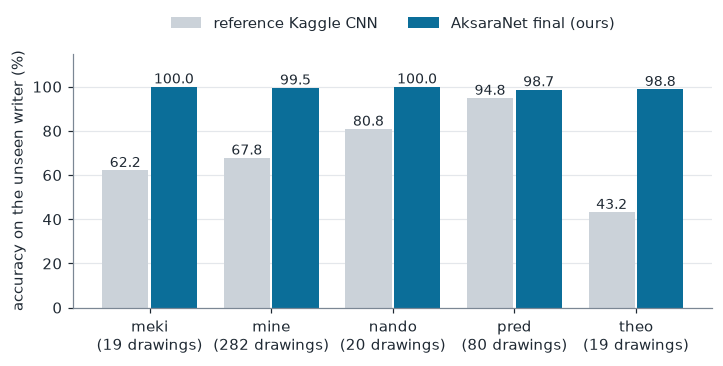

In [23]:
D = runs[runs.stage == "D"]
if len(D):
    fam = [s.split(":")[1] for s in D[D.name == "final"].split]
    wtab = pd.DataFrame({"held-out writer": fam,
                         "train images": D[D.name == "final"].n_train.values, "test images": D[D.name == "final"].n_test.values,
                         "test drawings": [len(set(ds.drawing[ds.family == f])) for f in fam],
                         "reference Kaggle CNN": D[D.name == "kaggle_cnn"].set_index("split").loc[[f"writer:{f}" for f in fam]].test_acc.values * 100,
                         "AksaraNet final (ours)": D[D.name == "final"].test_acc.values * 100}).set_index("held-out writer")
    display(wtab.style.format({"reference Kaggle CNN": "{:.2f}", "AksaraNet final (ours)": "{:.2f}"}))
    fig, ax = plt.subplots(figsize=(7.5, 3)); x = np.arange(len(fam))
    b1 = ax.bar(x - 0.2, wtab["reference Kaggle CNN"], 0.38, color="#cbd2d9", label="reference Kaggle CNN")
    b2 = ax.bar(x + 0.2, wtab["AksaraNet final (ours)"], 0.38, color=ACCENT, label="AksaraNet final (ours)")
    ax.bar_label(b1, fmt="%.1f", fontsize=9); ax.bar_label(b2, fmt="%.1f", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([f"{f}\n({n} drawings)" for f, n in zip(fam, wtab["test drawings"])]); ax.set_ylim(0, 115); ax.grid(axis="x", visible=False)
    ax.set_ylabel("accuracy on the unseen writer (%)"); ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.2))
    plt.savefig("figures/14_writers.png"); plt.show()

## 8. What has the network learned?

**First-layer filters.** In the lecture, edge detectors were hand-crafted kernels; here the 16 kernels of the first convolution are learned.

**Class activation maps (CAM, Zhou et al. 2016).** Because AksaraNet ends with global average pooling followed by one linear layer, the evidence for class *c* at each location of the last 8×8 feature map is simply the feature map weighted by the class weights, with no gradient computation.

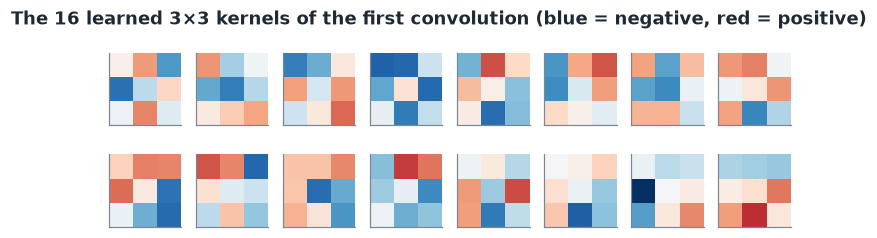

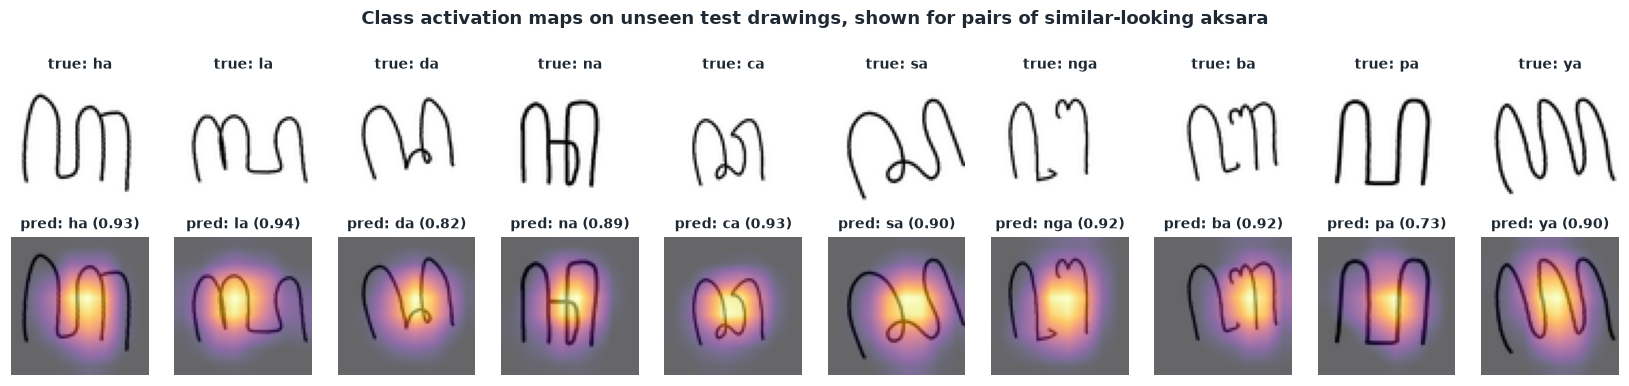

In [24]:
w = model.features[0].weight.detach().cpu().numpy()[:, 0]
fig, axes = plt.subplots(2, 8, figsize=(8, 2.2)); v = np.abs(w).max()
for ax, k in zip(axes.ravel(), w): ax.imshow(k, cmap="RdBu_r", vmin=-v, vmax=v); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("The 16 learned 3×3 kernels of the first convolution (blue = negative, red = positive)", fontweight="bold", y=1.03)
plt.savefig("figures/15_filters.png"); plt.show()

@torch.no_grad()
def cam(model, x):
    model.eval(); f = model.features(x)                       # (B, 128, 8, 8)
    Wc = model.classifier[-1].weight                          # (20, 128)
    logits = model.classifier(f)
    maps = torch.einsum("kc,bchw->bkhw", Wc, f)
    return logits.softmax(1).cpu().numpy(), torch.nn.functional.interpolate(maps, size=x.shape[-2:], mode="bilinear", align_corners=False).cpu().numpy()

pairs_show = [("ha", "la"), ("da", "na"), ("ca", "sa"), ("nga", "ba"), ("pa", "ya")]
rng = np.random.default_rng(1); te_set = set(te.tolist())
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for col, (a, b) in enumerate(pairs_show):
    for half, c in enumerate((a, b)):
        ci = ds.classes.index(c); k = rng.choice([i for i in np.where((ds.y == ci) & (ds.variant == "plain"))[0] if i in te_set])
        pr_, m = cam(model, X[k:k + 1]); top = int(pr_[0].argmax()); ax0, ax1 = axes[0, 2 * col + half], axes[1, 2 * col + half]
        ax0.imshow(ds.x(64)[k], cmap="gray", vmin=0, vmax=255); ax0.set_title(f"true: {c}", fontsize=9)
        ax1.imshow(ds.x(64)[k], cmap="gray", vmin=0, vmax=255); mm = np.maximum(m[0, top], 0)
        ax1.imshow(mm / (mm.max() + 1e-9), cmap="inferno", alpha=0.6, vmin=0, vmax=1); ax1.set_title(f"pred: {ds.classes[top]} ({pr_[0, top]:.2f})", fontsize=9)
        for ax in (ax0, ax1): ax.axis("off")
fig.suptitle("Class activation maps on unseen test drawings, shown for pairs of similar-looking aksara", fontweight="bold", y=1.02)
plt.tight_layout(h_pad=1.6); plt.savefig("figures/16_cam.png"); plt.show()

## 9. Application: transliterating handwritten words

The dataset ships eight photographs of handwritten words (`predict_test/`, file name = ground truth). This is a harder, out-of-distribution test: pen on paper photographed by a camera, whereas the training glyphs were drawn digitally.

The reference notebook cuts the word at every connected component and therefore breaks the aksara written with two separate strokes (its own "Drawbacks" section). Our reader (`hanacaraka/segment.py`):

1. Otsu binarisation, connected components → *primitives*, horizontally overlapping parts fused;
2. a **dynamic programme** chooses how to group consecutive primitives into glyphs, maximising Σ [log p(best class) − λ · inner gap / line height]: the classifier itself decides whether two strokes form one character;
3. each glyph is centred on a square canvas, resized to 64×64 and classified.

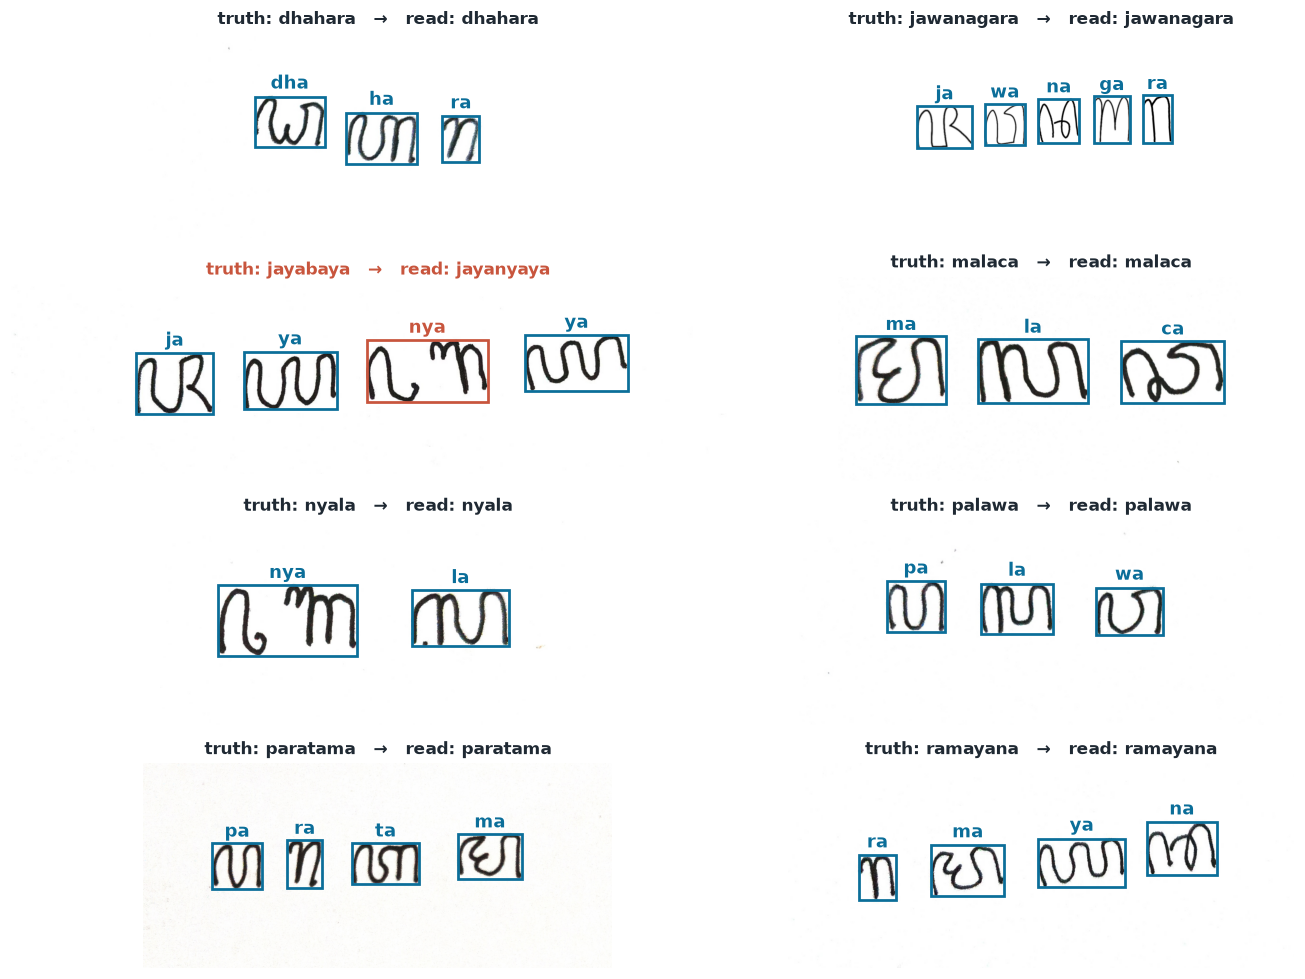

,glyphs,component-wise (reference approach),DP grouping (ours),glyphs correct (ours),word correct
word,,,,,
dhahara,3,dhahara,dhahara,3,True
jawanagara,5,jawaranagara,jawanagara,5,True
jayabaya,4,jayaparaya,jayanyaya,3,False
malaca,3,malaca,malaca,3,True
nyala,2,ngagala,nyala,2,True
palawa,3,palawa,palawa,3,True
paratama,4,paratama,paratama,4,True
ramayana,4,ramayana,ramayana,4,True


words read correctly: component-wise 5 / 8,  DP grouping 7 / 8;  glyph accuracy (ours) 27 / 28


In [25]:
from hanacaraka.segment import read_word, ink_mask
import re
ONSETS = sorted(ds.classes, key=len, reverse=True)
def syllables(word):
    out, i = [], 0
    while i < len(word):
        c = next(o for o in ONSETS if word.startswith(o, i)); out.append(c); i += len(c)
    return out

model_cpu = build(final_cfg["model"], size=final_cfg.get("size", 64), **final_cfg.get("model_kw", {})); model_cpu.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()})
files = sorted(os.listdir("predict_test")); rowsW = []
fig, axes = plt.subplots(4, 2, figsize=(13, 9))
for ax, f in zip(axes.ravel(), files):
    img = Image.open(os.path.join("predict_test", f)).convert("RGB"); truth = syllables(os.path.splitext(f)[0])
    cc, _, _ = read_word(model_cpu, img, ds.classes, mode="cc")
    dp, boxes, conf = read_word(model_cpu, img, ds.classes, mode="dp")
    rowsW.append({"word": "".join(truth), "glyphs": len(truth), "component-wise (reference approach)": "".join(cc), "DP grouping (ours)": "".join(dp),
                  "glyphs correct (ours)": sum(a == b for a, b in zip(dp, truth)) if len(dp) == len(truth) else 0, "word correct": "".join(dp) == "".join(truth)})
    ax.imshow(img); ax.axis("off")
    for (x0, y0, x1, y1), lab, cf, t in zip(boxes, dp, conf, truth + [None] * len(boxes)):
        good = lab == t
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=ACCENT if good else ACCENT2, linewidth=1.8))
        ax.text((x0 + x1) / 2, y0 - 8, lab, color=ACCENT if good else ACCENT2, fontsize=12, fontweight="bold", va="bottom", ha="center")
    ax.set_title(f"truth: {''.join(truth)}   →   read: {''.join(dp)}", color=INK if "".join(dp) == "".join(truth) else ACCENT2)
plt.tight_layout(); plt.savefig("figures/17_words.png"); plt.show()
W = pd.DataFrame(rowsW).set_index("word"); display(W)
print(f"words read correctly: component-wise {sum(W.iloc[:, 1] == W.index)} / {len(W)},  DP grouping {int(W['word correct'].sum())} / {len(W)};  glyph accuracy (ours) {W['glyphs correct (ours)'].sum()} / {W['glyphs'].sum()}")
W.to_csv("results/words.csv")

## 10. Conclusions

**1. Look at the data before the model.** The 12,000 images are ~29 augmented copies of each of only 420 hand-drawn characters. Splitting by drawing instead of by image changes the measured accuracy of an MLP from 95.3 % to 52.7 % and of the lecture CNN from 98.1 % to 64.7 %. All our numbers come from 5-fold cross-validation grouped by drawing, with validation folds for every decision.

**2. Architecture matters most.** Under that protocol: linear 42.1 %, MLP 52.7 %, LeNet-5 64.9 %, lecture CNN 64.7 %, HOG + SVM 74.5 %, reference Kaggle CNN 86.6 % (88.7 % with its own recipe), small ResNet 97.2 %, **AksaraNet 98.5 %**. The gain over the reference model comes from batch normalisation and from replacing the Flatten + Dense head by global average pooling, with 7× fewer parameters (296 k vs 2.08 M). Without batch normalisation the same network reaches only 48 % in the same budget.

**3. Learning strategy.** Optimiser and learning rate interact strongly: plain SGD works only at lr 0.1, while Adam / AdamW / RMSprop are within about one point of their best from 10⁻⁴ to 10⁻². Batch size, dropout, L2, label smoothing and the schedule each move validation accuracy by a few tenths of a point, inside fold-to-fold noise. Combining AdamW, a one-cycle schedule and strong online augmentation lifts validation accuracy from 99.3 % to 100 % on the tuning folds.

**4. Final model.** **99.41 % ± 0.78** test accuracy (mean ± sd over 5 folds, 3 seeds each; macro-F1 99.40 %); **99.64 %** as a 3-seed ensemble, 95 % cluster-bootstrap interval [99.02, 99.99]. All 43 remaining errors come from 4 of the 420 drawings, 31 of them from a single *na* read as *ka*. On the original Kaggle split the model scores 99.94 % (ensemble 100 %), against 96.5 % published and 96.8 % for our re-implementation of the reference notebook.

**5. Generalisation.** On writers that were completely held out, AksaraNet keeps 98.7 to 100 % while the reference CNN drops to 43 to 95 %. Augmentation and the weight-free head, not extra capacity, are what make the model robust to a new hand.

**6. Application.** Letting the classifier decide which strokes belong to one glyph (dynamic programming over connected components) reads 7 of 8 photographed words and 27 of 28 glyphs; the reference component-wise segmentation reads 5 of 8.

**Limitations.** (i) Only 420 drawings by about five writers, three of them with ~20 drawings each: the unseen-writer scores have wide uncertainty. (ii) Accuracy is at the ceiling of this dataset, so the tuning experiments cannot rank the good configurations; a harder benchmark is needed. (iii) Only the 20 base characters are covered: no *sandhangan* (vowel marks), *pasangan* (conjuncts) or numerals, so this is not yet a full Javanese OCR. (iv) Word reading was tested on eight clean, well-spaced words only. (v) Writer tags were inferred from file names.

**Future work.** Collect glyphs from more writers; extend the label set to sandhangan and pasangan; replace segmentation + classification by a sequence model (CNN + recurrent layers with CTC loss) trained on whole words; compare with transfer learning from a pretrained backbone.

## 11. The same model in Keras, and a framework comparison

The lecture examples are written in Keras, while the experiments above use PyTorch. To show that the results belong to the *method* and not to the framework, AksaraNet was ported to **Keras 3 (TensorFlow backend)** and trained again on exactly the same five folds (the fold assignment is exported by the PyTorch pipeline to `cache/folds_seed0.npy`).

Keras lives in its own Python environment (`keras-lecture`), so the cells below call that interpreter; the code is in `hanacaraka_keras/aksaranet.py` and `scripts/run_keras.py`.

| | PyTorch (`hanacaraka/`) | Keras (`hanacaraka_keras/`) |
|---|---|---|
| Model definition | `nn.Sequential` of `Conv2d`, `BatchNorm2d`, `ReLU`, `MaxPool2d`, `AdaptiveAvgPool2d`, `Dropout`, `Linear` | `keras.Sequential` of `Conv2D`, `BatchNormalization`, `Activation`, `MaxPooling2D`, `GlobalAveragePooling2D`, `Dropout`, `Dense(softmax)` |
| Image layout | channels first, 1×64×64 | channels last, 64×64×1 |
| BatchNorm momentum | 0.1 | 0.9 (same quantity, opposite convention) |
| Loss | `F.cross_entropy` on logits, integer labels | `categorical_crossentropy` on softmax output, one-hot labels |
| Training loop | hand-written loop (`train.fit`) | `model.compile` + `model.fit` |
| Augmentation | `data.augment` (`affine_grid` + `grid_sample`) | custom layer `RandomAffineStroke` (`ops.image.affine_transform`) |
| One-cycle schedule | `OneCycleLR` | custom `LearningRateSchedule` |
| Best-epoch selection | in the loop | `EarlyStopping(restore_best_weights=True)` |
| Device used here | Apple GPU (MPS) | CPU (no GPU plug-in installed) |

In [26]:
from IPython.display import Code
Code(filename="hanacaraka_keras/aksaranet.py", language="python")

"""AksaraNet in Keras, written in the style of the lecture examples.

The network, the augmentation and the learning-rate schedule mirror the PyTorch implementation in
hanacaraka/models.py, hanacaraka/data.py and hanacaraka/train.py.
"""
import math

import keras
from keras import layers, ops


def build_aksaranet(size=64, n_classes=20, widths=(16, 32, 64, 128), depth=2, dropout=0.3, augment=None):
    """4 stages of [Conv 3x3 - BatchNorm - ReLU] x depth, max-pooling between stages,
    global average pooling, dropout, softmax. `augment`: optional dict for RandomAffineStroke."""
    model = keras.Sequential(name="AksaraNet")
    model.add(keras.Input(shape=(size, size, 1)))
    if augment:
        model.add(RandomAffineStroke(**augment))                      # active only while training
    for i, w in enumerate(widths):
        for _ in range(depth):
            model.add(layers.Conv2D(w, (3, 3), padding="same", use_bias=False))
            model.add(layers.BatchNormalization(momentum=0.9, epsilon=1e-5))   # = PyTorch momentum 0.1
            model.add(layers.Activation("relu"))
        if i < len(widths) - 1:
            model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_classes, activation="softmax"))
    return model


class RandomAffineStroke(layers.Layer):
    """Online augmentation: random rotation, anisotropic scale, shear and shift (one affine warp),
    then random thickening or thinning of the pen stroke. Ink = 1, paper = 0."""

    def __init__(self, rot=20, scale=0.25, shift=0.12, shear=15, thick=0.5, seed=0, **kw):
        super().__init__(**kw)
        self.rot, self.scale, self.shift, self.shear, self.thick = rot, scale, shift, shear, thick
        self.seed = seed
        self.rng = keras.random.SeedGenerator(seed)

    def call(self, x, training=False):
        if not training:
            return x
        b, w = ops.shape(x)[0], float(x.shape[1])
        u = lambda: keras.random.uniform((b,), -1.0, 1.0, seed=self.rng)
        a, sh = u() * math.radians(self.rot), u() * math.radians(self.shear)
        sx, sy = 1 + u() * self.scale, 1 + u() * self.scale
        t00, t01, t02 = sx * ops.cos(a), -sy * ops.sin(a + sh), u() * self.shift * 2
        t10, t11, t12 = sx * ops.sin(a), sy * ops.cos(a + sh), u() * self.shift * 2
        # the matrix above is in normalised [-1, 1] coordinates; convert the offsets to pixels
        a2 = (t00 + t01) * (1 - w) / 2 + t02 * w / 2 + (w - 1) / 2
        b2 = (t10 + t11) * (1 - w) / 2 + t12 * w / 2 + (w - 1) / 2
        zero = ops.zeros_like(a)
        x = ops.image.affine_transform(x, ops.stack([t00, t01, a2, t10, t11, b2, zero, zero], axis=1),
                                       interpolation="bilinear", fill_mode="constant", fill_value=0.0)
        if self.thick > 0:
            p = keras.random.uniform((b, 1, 1, 1), 0.0, 1.0, seed=self.rng)
            thicker = ops.max_pool(x, 3, 1, "same")
            thinner = -ops.max_pool(-x, 3, 1, "same")
            x = ops.where(p < self.thick * 0.6, thicker, ops.where(p > 1 - self.thick * 0.4, thinner, x))
        return x

    def get_config(self):
        return {**super().get_config(), "rot": self.rot, "scale": self.scale, "shift": self.shift,
                "shear": self.shear, "thick": self.thick, "seed": self.seed}


class OneCycle(keras.optimizers.schedules.LearningRateSchedule):
    """One-cycle learning rate (Smith & Topin): cosine warm-up from peak/25 to peak over the first
    25 % of the steps, then cosine decay to peak/250,000."""

    def __init__(self, peak, total_steps, pct_start=0.25, div=25.0, final_div=1e4):
        self.peak, self.total_steps, self.pct_start, self.div, self.final_div = peak, total_steps, pct_start, div, final_div

    def __call__(self, step):
        step = ops.cast(step, "float32")
        up = self.pct_start * self.total_steps - 1
        down = self.total_steps - 1 - up
        cos = la

In [27]:
KERAS_PY = "/opt/anaconda3/envs/keras-lecture/bin/python"      # interpreter of the Keras environment
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
!MPLBACKEND=agg {KERAS_PY} -c "import sys; sys.path.insert(0, '.'); from hanacaraka_keras.aksaranet import build_aksaranet; build_aksaranet().summary()"

Model: "AksaraNet"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 16)   

The Keras model has the same **296,292 trainable parameters** as the PyTorch one (Keras additionally lists the 960 BatchNorm running statistics as non-trainable).

Two training setups are used on all five rotations, seed 0 (the slides call them *baseline training* and *tuned training*):

* **reference**: Adam 10⁻³, batch 64, no augmentation, early stopping with patience 6 (the recipe of Experiment 1);
* **final**: AdamW, one-cycle schedule peaking at 3·10⁻³, strong online augmentation, label smoothing 0.1, 25 epochs (the recipe of Experiment 3).

In [28]:
if not os.path.exists("results/keras_runs.jsonl"):
    !MPLBACKEND=agg {KERAS_PY} scripts/run_keras.py reference final
kr = pd.DataFrame([json.loads(l) for l in open("results/keras_runs.jsonl")])
print("framework:", kr.framework.iloc[0])

pt = {"reference": runs[(runs.stage == "A") & (runs.name == "aksaranet")], "final": runs[(runs.stage == "C") & (runs.name == "final") & (runs.seed == 0)]}
rows = []
for recipe in ("reference", "final"):
    a = pt[recipe].set_index("split").sort_index(); b = kr[kr.name == recipe].set_index("split").sort_index()
    for split in b.index:
        rows.append({"recipe": recipe, "fold": split, "PyTorch test acc": a.test_acc[split] * 100, "Keras test acc": b.test_acc[split] * 100,
                     "PyTorch val acc": a.val_acc[split] * 100, "Keras val acc": b.val_acc[split] * 100,
                     "PyTorch s/epoch (GPU)": a.seconds[split] / a.epochs_run[split], "Keras s/epoch (CPU)": b.seconds[split] / b.epochs_run[split]})
cmp_ = pd.DataFrame(rows); cmp_["difference (points)"] = cmp_["Keras test acc"] - cmp_["PyTorch test acc"]
display(cmp_.set_index(["recipe", "fold"]).style.format("{:.2f}"))
agg = cmp_.groupby("recipe", sort=False).agg(**{"PyTorch mean": ("PyTorch test acc", "mean"), "PyTorch sd": ("PyTorch test acc", "std"),
                                                "Keras mean": ("Keras test acc", "mean"), "Keras sd": ("Keras test acc", "std"),
                                                "mean difference": ("difference (points)", "mean"), "sd of difference": ("difference (points)", "std")})
display(agg.style.format("{:.2f}")); agg.to_csv("results/keras_vs_pytorch.csv")

framework: keras 3.15.1 (tensorflow)


,PyTorch mean,PyTorch sd,Keras mean,Keras sd,mean difference,sd of difference
recipe,,,,,,
reference,98.52,1.05,97.97,0.74,-0.55,0.58
final,99.47,0.66,99.02,1.26,-0.46,0.79


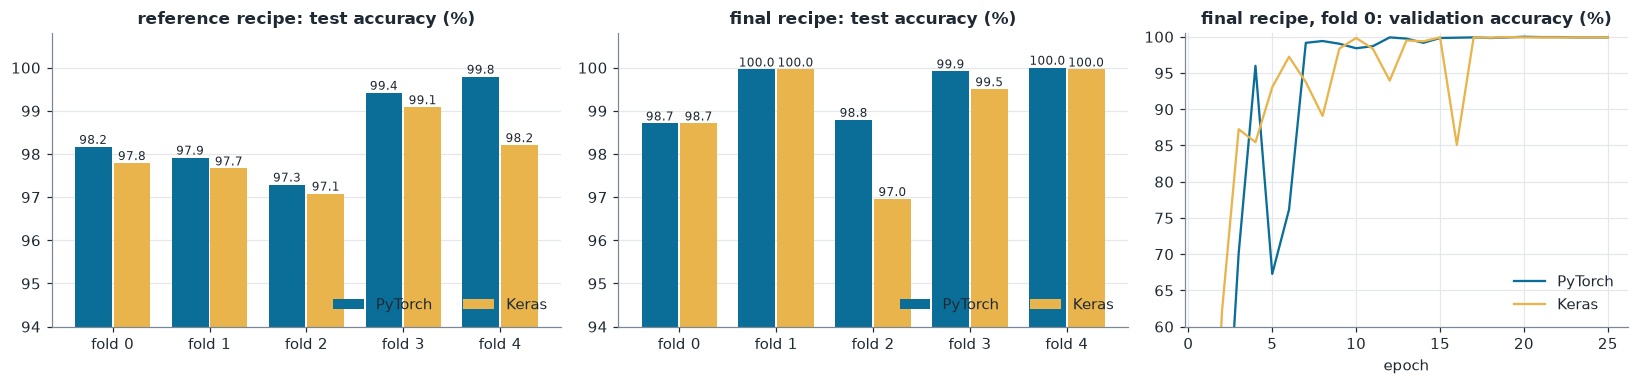

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})
for ax, recipe in zip(axes[:2], ("reference", "final")):
    d = cmp_[cmp_.recipe == recipe]; x = np.arange(len(d))
    b1 = ax.bar(x - 0.2, d["PyTorch test acc"], 0.38, color=ACCENT, label="PyTorch"); b2 = ax.bar(x + 0.2, d["Keras test acc"], 0.38, color="#e9b44c", label="Keras")
    ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([f"fold {s[-1]}" for s in d.fold]); ax.set_ylim(94, 100.8); ax.grid(axis="x", visible=False)
    ax.set_title(f"{recipe} recipe: test accuracy (%)"); ax.legend(loc="lower right", ncol=2)
ax = axes[2]
hk = kr[(kr.name == "final") & (kr.split == "rot0")].iloc[0]["hist"]; hp = pt["final"][pt["final"].split == "rot0"].iloc[0]["hist"]
ax.plot(np.arange(1, len(hp["val_acc"]) + 1), np.array(hp["val_acc"]) * 100, color=ACCENT, label="PyTorch")
ax.plot(np.arange(1, len(hk["val_accuracy"]) + 1), np.array(hk["val_accuracy"]) * 100, color="#e9b44c", label="Keras")
ax.set_ylim(60, 100.5); ax.set_xlabel("epoch"); ax.set_title("final recipe, fold 0: validation accuracy (%)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/18_keras_vs_pytorch.png"); plt.show()

**Reading the comparison.**

* **Same conclusion in both frameworks.** With the Experiment 1 recipe Keras reaches 97.97 % against 98.52 % for PyTorch; with the final recipe 99.02 % against 99.47 % (mean test accuracy over the same five folds, one seed each). The final recipe improves on the reference recipe by about one point in both, and fold by fold the two implementations rise and fall together (folds 1, 3, 4 are easy; fold 2 is the hard one).
* **The gap is inside the noise.** Keras is about half a point lower on average, but the paired differences have a standard deviation of 0.6 to 0.8 points over five folds, and most of the gap in the final recipe comes from fold 2 alone (96.96 % vs 98.79 %). On that same fold the three PyTorch seeds of §6.2 range from 97.21 % to 99.29 %, so one seed per framework cannot separate a framework effect from seed variance. We do not claim that either framework is more accurate.
* **The port is faithful but not bit-identical.** Remaining differences: weight initialisation (Glorot-uniform in Keras, Kaiming-uniform in PyTorch); PyTorch's `OneCycleLR` also cycles Adam's β₁ between 0.85 and 0.95 while the Keras schedule changes only the learning rate; the random number streams, hence the augmentations and batch order, differ; ties in best-epoch selection are broken differently.
* **Speed is about the device, not the framework.** Keras ran on the CPU (about 25 s per epoch) and PyTorch on the Apple GPU (about 5 s per epoch); no conclusion about framework speed should be drawn from these timings.

### Save, load and predict, as in the lecture

The Keras model of fold 0 was saved with `model.save("results/aksaranet_keras.keras")`. `scripts/keras_predict.py` reloads it with `keras.models.load_model` and predicts a few unseen test images, following the lecture's *load model and prediction* step.

In [30]:
!MPLBACKEND=agg {KERAS_PY} scripts/keras_predict.py

test accuracy of the reloaded model on fold 0: 0.9871
label actual: ba | label prediction: ba (0.95)
label actual: dha | label prediction: dha (0.91)
label actual: ja | label prediction: ja (0.90)
label actual: na | label prediction: ka (0.79)
label actual: pa | label prediction: pa (0.73)
label actual: ta | label prediction: ta (0.93)
label actual: ya | label prediction: ya (0.94)
label actual: sa | label prediction: sa (0.91)


## References

1. *Javanese Script (Aksara Jawa) Augmented*, Kaggle dataset (kaggle.com/datasets, folder `javanese-script-aksara-jawa-augmented`); and the reference notebook *Javanese Script Classification & Recognition* (CNN + contour segmentation, 96.5 % test accuracy).
2. Afiahayati, *Introduction to Deep Learning*, lecture slides, Dept. of Computer Science and Electronics, Universitas Gadjah Mada.
3. Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, "Gradient-based learning applied to document recognition", *Proc. IEEE*, 1998.
4. K. Simonyan, A. Zisserman, "Very deep convolutional networks for large-scale image recognition", ICLR 2015.
5. K. He, X. Zhang, S. Ren, J. Sun, "Deep residual learning for image recognition", CVPR 2016.
6. S. Ioffe, C. Szegedy, "Batch normalization: accelerating deep network training by reducing internal covariate shift", ICML 2015.
7. M. Lin, Q. Chen, S. Yan, "Network in network", ICLR 2014 (global average pooling).
8. N. Srivastava et al., "Dropout: a simple way to prevent neural networks from overfitting", JMLR 2014.
9. D. Kingma, J. Ba, "Adam: a method for stochastic optimization", ICLR 2015; I. Loshchilov, F. Hutter, "Decoupled weight decay regularization", ICLR 2019.
10. L. Smith, N. Topin, "Super-convergence: very fast training of neural networks using large learning rates", 2018 (one-cycle schedule).
11. B. Zhou et al., "Learning deep features for discriminative localization", CVPR 2016 (class activation maps).
12. N. Dalal, B. Triggs, "Histograms of oriented gradients for human detection", CVPR 2005.
13. S. Kaufman, S. Rosset, C. Perlich, "Leakage in data mining: formulation, detection, and avoidance", ACM TKDD 2012.
14. P. Simard, D. Steinkraus, J. Platt, "Best practices for convolutional neural networks applied to visual document analysis", ICDAR 2003 (elastic / affine augmentation for handwriting).